In [1]:
import polars as pl
from Model_Building.ModelBuilder import ModelBuilder
import plotly.express as px
from Model_Evaluation.evaluation import (
    gini,
    shap_plot,
    metrics_table,
    nil_metrics,
    sev_metrics,
    AvE_by_feature,
    plot_ave,
)

/Users/johnwragg/Desktop/DS_work/Hastings_Solution/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
mb = ModelBuilder.load(
    r"/Users/johnwragg/Desktop/DS_work/Hastings_Solution/Model_Experiments/test_run.joblib"
)

In [3]:
# Test predictions
train = pl.read_parquet(
    r"/Users/johnwragg/Desktop/DS_work/Hastings_Solution/Prepped_Data/train.parquet"
)

In [4]:
test = pl.read_parquet(
    r"/Users/johnwragg/Desktop/DS_work/Hastings_Solution/Prepped_Data/test.parquet"
)

In [5]:
preds = mb.predict(test)

In [6]:
preds

p_nonnil,severity_capped,expected_capped,expected_cost
f64,f64,f64,f64
0.96537,7040.06303,6796.264736,10503.576883
0.699753,2055.395479,1438.269214,2222.834432
0.689106,1515.013701,1044.00537,1613.502578
0.722771,2753.82118,1990.382482,3076.121404
0.847995,2034.531805,1725.272915,2666.396529
…,…,…,…
0.61107,1261.70468,770.990029,1191.559387
0.77048,2945.408052,2269.377405,3507.305995
0.604225,2479.442511,1498.140473,2315.365021


In [7]:
comparison = pl.concat([test, preds], how="horizontal")

In [8]:
comparison.head()

Claim_Number,date_of_loss,Notifier,Notification_period,Inception_to_loss,Location_of_incident,Weather_conditions,Vehicle_mobile,Time_hour,Main_driver,PH_considered_TP_at_fault,Incident_details_present,Injury_details_present,TP_type_insd_pass_back,TP_type_driver,TP_type_pass_back,TP_type_pass_front,TP_type_other,TP_type_nk,TP_injury_whiplash,TP_injury_traumatic,TP_injury_fatality,TP_injury_unclear,TP_injury_nk,Incurred,Capped_Incurred,loss_year,loss_month,non_zero_claim_flag,tp_total,tp_passengers,tp_bike_pedest,tp_injured_known,tp_serious_injury_flag,tp_region,tp_region_total,p_nonnil,severity_capped,expected_capped,expected_cost
i64,date,cat,i64,i64,cat,cat,cat,i64,cat,cat,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i32,i8,i32,i64,i64,i64,i64,bool,cat,i64,f64,f64,f64,f64
325,2004-10-14,"""PH""",1,60,"""Main Road""","""WET""","""N""",16,"""Other""","""n/k""",1,0,0,0,0,0,0,2,0,0,0,2,0,2846.297554,2846.297554,2004,10,1,2,0,0,0,false,"""southe""",2,0.96537,7040.06303,6796.264736,10503.576883
102,2004-01-13,"""PH""",0,205,"""Minor Road""","""NORMAL""","""Y""",9,"""Other""","""n/k""",1,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2004,1,0,0,0,0,0,false,"""none""",0,0.699753,2055.395479,1438.269214,2222.834432
7507,2015-05-26,"""Other""",51,48,"""Minor Road""","""WET""","""Y""",8,"""N""","""N""",1,0,0,1,0,0,0,0,0,0,0,1,1,0.0,0.0,2015,5,0,1,0,0,0,false,"""none""",0,0.689106,1515.013701,1044.00537,1613.502578
7564,2015-06-08,"""Other""",0,30,"""Main Road""","""N/K""","""Y""",7,"""Other""","""N""",1,0,0,1,0,0,0,0,0,0,0,1,0,0.0,0.0,2015,6,0,1,0,0,0,false,"""southe""",1,0.722771,2753.82118,1990.382482,3076.121404
120,2004-02-05,"""Other""",1,102,"""Main Road""","""NORMAL""","""Y""",20,"""Other""","""n/k""",1,0,0,0,0,0,0,1,0,0,0,1,0,247.14429,247.14429,2004,2,1,1,0,0,0,false,"""eastmid""",1,0.847995,2034.531805,1725.272915,2666.396529


In [9]:
# Testing functions

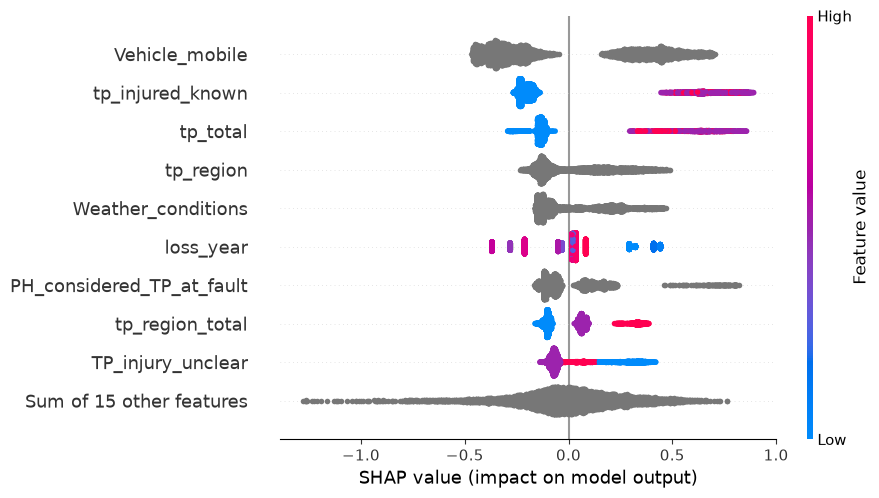

In [10]:
shap_plot(mb, train, model="nil")

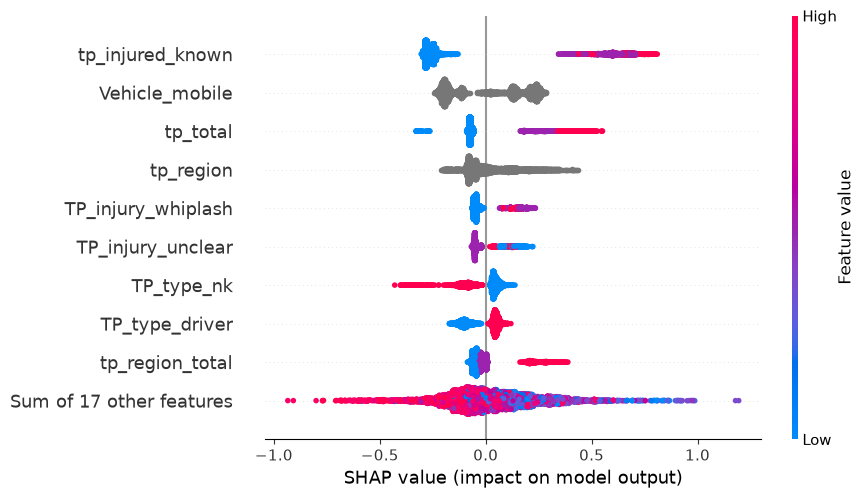

In [11]:
shap_plot(mb, train, model="sev")

In [12]:
preds.columns

['p_nonnil', 'severity_capped', 'expected_capped', 'expected_cost']

In [13]:
from params.targets import TARGET_COL

ave_sev_tp_injured_known = AvE_by_feature(
    comparison,
    mb.sev_model,
    target=TARGET_COL,
    pred="severity_capped",
    feature="tp_injured_known",
)

In [14]:
ave_sev_tp_injured_known

tp_injured_known,severity_capped,Capped_Incurred,count
i64,f64,f64,u32
0,3470.401242,2489.342751,1157
1,15612.425285,14996.077913,251
2,22354.929248,21411.285907,82
3,26361.893149,26985.598036,22
4,31837.450256,31182.519904,9
5,28517.740681,34740.537222,5
6,26706.502155,36682.359547,1
7,30712.468627,50000.0,2


In [15]:
plot_ave(ave_sev_tp_injured_known)

In [16]:
sev_metrics(comparison)

{'claims': 1178,
 'gini': np.float64(0.7479464092159411),
 'gamma_pde': 0.3479435556238508}

In [17]:
nil_metrics(comparison)

{'claims': 1529,
 'non_nil_rate': np.float64(0.7704381948986265),
 'auc': 0.7821117447603017,
 'log_loss': 0.4442953256292986,
 'accuracy': 0.7678221059516024,
 'precision': 0.7778528021607022,
 'recall': 0.9779286926994907,
 'f1': 0.8664911620910116}

In [19]:
preds_train = mb.predict(train)

In [20]:
comparison_train = pl.concat([train, preds_train], how="horizontal")

In [23]:
metrics_table_nil = metrics_table(comparison_train, comparison, nil_metrics)

In [24]:
metrics_table_sev = metrics_table(comparison_train, comparison, sev_metrics)

In [26]:
metrics_table_nil.filter(pl.col("dataset") == "train")

dataset,loss_year,claims,non_nil_rate,auc,log_loss,accuracy,precision,recall,f1
str,str,i64,f64,f64,f64,f64,f64,f64,f64
"""train""","""all""",6114,0.770527,0.785737,0.443074,0.774616,0.781456,0.982169,0.870391
"""train""","""2003""",73,0.876712,0.746528,0.338635,0.876712,0.876712,1.0,0.934307
"""train""","""2004""",259,0.849421,0.848368,0.336931,0.849421,0.849421,1.0,0.91858
"""train""","""2005""",189,0.915344,0.836344,0.245045,0.915344,0.915344,1.0,0.955801
"""train""","""2006""",290,0.872414,0.826407,0.315222,0.872414,0.872414,1.0,0.93186
…,…,…,…,…,…,…,…,…,…
"""train""","""2011""",430,0.695349,0.739922,0.532255,0.704651,0.734973,0.899666,0.809023
"""train""","""2012""",663,0.73454,0.744738,0.500294,0.749623,0.777202,0.924025,0.844278
"""train""","""2013""",805,0.737888,0.777076,0.475153,0.741615,0.745547,0.986532,0.849275


In [27]:
metrics_table_sev.filter(pl.col("dataset") == "train")

dataset,loss_year,claims,gini,gamma_pde
str,str,i64,f64,f64
"""train""","""all""",4711,0.761861,0.36085
"""train""","""2003""",64,0.751218,0.314704
"""train""","""2004""",220,0.726902,0.299391
"""train""","""2005""",173,0.750961,0.358245
"""train""","""2006""",253,0.738296,0.32473
…,…,…,…,…
"""train""","""2011""",299,0.773813,0.39704
"""train""","""2012""",487,0.78341,0.396231
"""train""","""2013""",594,0.716644,0.309277


In [26]:
from sklearn.metrics import mean_gamma_deviance

In [27]:
comp_pos = comparison.filter(pl.col("Capped_Incurred") > 0)

In [28]:
mean_gamma_deviance(
    comp_pos.select("Capped_Incurred"), comp_pos.select("severity_capped")
)

1.691078517900689

In [9]:
import shap

/Users/johnwragg/Desktop/DS_work/Hastings_Solution/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
from params.targets import NIL_TARGET

In [26]:
def shap_plot(mb, data: pl.DataFrame, model: str):
    is_sev = model == "sev"
    model = mb.sev_model if is_sev else mb.nil_model
    features = mb.sev_features if is_sev else mb.nil_features
    rows = data.filter(pl.col(NIL_TARGET) == 1) if is_sev else data
    X = rows.select(features).to_pandas()

    explainer = shap.Explainer(model, feature_perturbation="tree_path_dependent")
    shap_values = explainer(X)

    return shap.plots.beeswarm(shap_values)

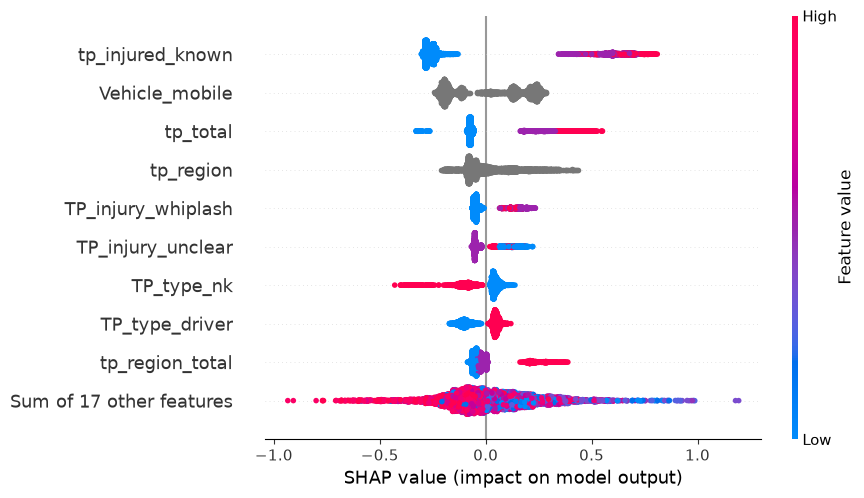

In [29]:
shap_plot(mb, train, model="sev")

In [33]:
# AvE
# get preds vs actuals
comparison.head()

Capped_Incurred,p_nonnil,severity_capped,expected_capped,expected_cost
f64,f64,f64,f64,f64
2846.297554,0.96537,7040.06303,6796.264736,10503.576883
0.0,0.699753,2055.395479,1438.269214,2222.834432
0.0,0.689106,1515.013701,1044.00537,1613.502578
0.0,0.722771,2753.82118,1990.382482,3076.121404
247.14429,0.847995,2034.531805,1725.272915,2666.396529


In [40]:
train.group_by("loss_year").agg(
    pl.col("Capped_Incurred").mean(), pl.col("Incurred").mean()
).sort("loss_year")

loss_year,Capped_Incurred,Incurred
i32,f64,f64
2003,4752.472257,5034.47804
2004,6077.983271,8109.095004
2005,5681.992683,9419.623431
2006,5247.853462,5474.840804
2007,5719.506188,9710.318189
…,…,…
2011,7284.01295,13607.737869
2012,6497.840642,10663.651097
2013,6014.143228,7117.536146


In [ ]:
preds = mb.predict

In [52]:
def AvE_by_feature(data, model, target, pred, feature):
    is_sev = model == "sev"
    rows = data.filter(pl.col(NIL_TARGET) == 1) if is_sev else data
    base_plot_data = (
        rows.group_by(feature)
        .agg(
            pl.col(pred).mean(),
            pl.col(target).mean(),
            pl.len().alias("count"),
        )
        .sort(feature)
    )

    return base_plot_data

In [44]:
preds.columns

['p_nonnil', 'severity_capped', 'expected_capped', 'expected_cost']

In [56]:
res = AvE_by_feature(
    comparison,
    model="sev",
    target="Capped_Incurred",
    pred="expected_capped",
    feature="loss_year",
)

In [57]:
res

loss_year,expected_capped,Capped_Incurred,count
i32,f64,f64,u32
2003,8080.63632,11951.49545,17
2004,3954.450281,4514.366961,40
2005,5727.054278,6134.586237,42
2006,6650.429475,5707.843522,68
2007,5263.256629,6671.579844,77
…,…,…,…
2011,9827.497768,10107.256435,109
2012,8519.733295,10056.956712,107
2013,8447.077182,7507.340153,141


In [60]:
from plotly.subplots import make_subplots

feature = res.columns[0]

bars = px.histogram(res, x=feature, y="count", color_discrete_sequence=["#c3c2b7"])
bars.update_traces(name="Claims", showlegend=True)

lines = px.line(
    res,
    x=feature,
    y=["expected_capped", "Capped_Incurred"],
    markers=True,
    color_discrete_sequence=["#2a78d6", "#eb6834"],
)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_traces(bars.data, secondary_ys=[False])
fig.add_traces(lines.data, secondary_ys=[True, True])

fig.update_xaxes(type="category", title=feature)
fig.update_yaxes(title="Claims", showgrid=False, secondary_y=False)
fig.update_yaxes(title="Mean capped incurred", rangemode="tozero", secondary_y=True)
fig.update_layout(
    title=f"Actual vs expected by {feature}",
    bargap=0.1,
    legend_title_text="",
)
fig.show()

In [46]:
train["TP_injury_fatality"]

TP_injury_fatality
i64
0
0
0
0
0
…
0
0
0


In [12]:
mb.sev_model.n_features_

26

In [26]:
shap_plot(mb, train, model="sev")

[LightGBM] [Fatal] The number of features in data (24) is not the same as it was in training data (26).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.


LightGBMError: The number of features in data (24) is not the same as it was in training data (26).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.

In [ ]:
def shap_values(
    mb, data: pl.DataFrame, part: str = "sev"
) -> tuple[np.ndarray, pd.DataFrame]:
    """Raw SHAP matrix and the feature frame, e.g. for shap.summary_plot(values, X_codes)."""
    model = mb.sev_model
    features = mb.sev_features
    rows = data.filter(pl.col(NIL_TARGET) == 1) if part == "sev" else data
    X = rows.select(features).to_pandas()
    return model.booster_.predict(X, pred_contrib=True)[:, :-1], X

In [10]:
from params.targets import NIL_TARGET

In [15]:
model = mb.sev_model
features = mb.sev_features
X = train.select(features).to_pandas()

In [16]:
import shap

In [21]:
explainer = shap.Explainer(model, feature_perturbation="tree_path_dependent")
shap_values = explainer(X)

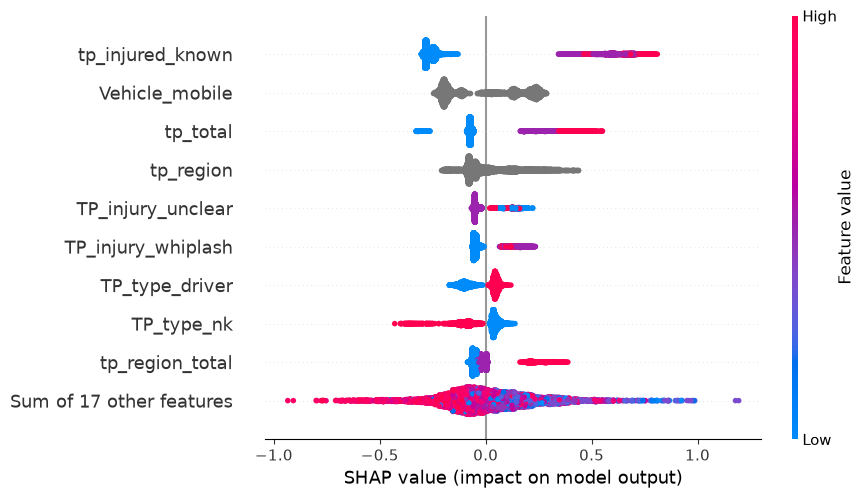

In [23]:
shap.plots.beeswarm(shap_values)

In [22]:
shap_values

.values =
array([[ 0.00431413,  0.00504416, -0.00775018, ..., -0.02044211,
         0.09462614, -0.02286453],
       [-0.03055545,  0.04134838,  0.19950019, ..., -0.02173151,
        -0.06522692, -0.0581487 ],
       [ 0.0039044 ,  0.01580841, -0.11154078, ..., -0.02253803,
        -0.04768625, -0.05937706],
       ...,
       [ 0.00156442,  0.01317126, -0.02599427, ..., -0.02184512,
        -0.04392005,  0.00145841],
       [ 0.00876831,  0.01371559, -0.01798487, ..., -0.02192689,
        -0.00040651,  0.00058295],
       [-0.03327749, -0.40352414, -0.00769082, ..., -0.02359947,
        -0.08009884, -0.06120074]], shape=(6114, 26))

.base_values =
array([8.51228796, 8.51228796, 8.51228796, ..., 8.51228796, 8.51228796,
       8.51228796], shape=(6114,))

.data =
array([['PH', 0, 128, ..., False, 'northw', 1],
       ['Other', 1, 13, ..., False, 'none', 0],
       ['PH', 0, 221, ..., False, 'none', 0],
       ...,
       ['PH', 0, 177, ..., False, 'southe', 1],
       ['PH', 0, 103, ...

In [17]:
# Model checks: summary table, then decile calibration, then large claims
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score

train = pl.read_parquet(
    r"/Users/johnwragg/Desktop/DS_work/Hastings_Solution/Prepped_Data/train.parquet"
)
all_claims = pl.concat([train, test])


def gini(actual, pred):
    """Ranking quality: 1 = perfect order, 0 = random."""
    area = lambda order: (np.cumsum(actual[order]) / actual.sum()).mean() - 0.5
    return area(np.argsort(-pred, kind="stable")) / area(
        np.argsort(-actual, kind="stable")
    )


def score(name, model, data):
    p = model.predict(data)
    capped, uncapped = data["Capped_Incurred"].to_numpy(), data["Incurred"].to_numpy()
    expected, expected_cost = (
        p["expected_capped"].to_numpy(),
        p["expected_cost"].to_numpy(),
    )
    return {
        "check": name,
        "claims": data.height,
        "auc": roc_auc_score(data["non_zero_claim_flag"], p["p_nonnil"]),
        "gini": gini(capped, expected),
        "r2_capped": r2_score(capped, expected),
        "mae_capped": mean_absolute_error(capped, expected),
        "ae_capped": capped.sum() / expected.sum(),
        "r2_uncapped": r2_score(uncapped, expected_cost),
        "ae_uncapped": uncapped.sum() / expected_cost.sum(),
    }


def refit(nil_features, sev_features, data):
    return ModelBuilder(nil_features, {}, sev_features, {}).fit(data)


# Overfitting: train vs test
results = [score("train", mb, train), score("test", mb, test)]

# Future claims: train on earlier years only, score the next year
for year in [2014, 2015]:
    past = all_claims.filter(pl.col("loss_year") < year)
    future = all_claims.filter(pl.col("loss_year") == year)
    results.append(
        score(f"backtest {year}", refit(mb.nil_features, mb.sev_features, past), future)
    )

# Injury dependence: the key feature on its own, then removed
key = "tp_injured_known"
results.append(score("only injury feature", refit([key], [key], train), test))
results.append(
    score(
        "without injury feature",
        refit(
            [f for f in mb.nil_features if f != key],
            [f for f in mb.sev_features if f != key],
            train,
        ),
        test,
    )
)

display(pl.DataFrame(results))

# Calibration: predicted vs actual by decile (1 = lowest risk)
scored = pl.concat([test, preds], how="horizontal").with_columns(
    decile=(pl.col("expected_capped").rank("ordinal") - 1) * 10 // pl.len() + 1,
    at_cap=pl.col("Capped_Incurred") >= 50000,
)
deciles = (
    scored.group_by("decile")
    .agg(
        claims=pl.len(),
        pred_capped=pl.col("expected_capped").mean(),
        actual_capped=pl.col("Capped_Incurred").mean(),
        pred_uncapped=pl.col("expected_cost").mean(),
        actual_uncapped=pl.col("Incurred").mean(),
        at_cap=pl.col("at_cap").sum(),
    )
    .sort("decile")
)
display(deciles)

# Large claims: can the model find them?
top_20_pct = deciles.filter(pl.col("decile") >= 9)["at_cap"].sum()
print(
    f"Claims at cap: {deciles['at_cap'].sum()}, of which in top 20% of predictions: {top_20_pct}"
)
print(f"Highest capped prediction: {scored['expected_capped'].max():,.0f}")

check,claims,auc,gini,r2_capped,mae_capped,ae_capped,r2_uncapped,ae_uncapped
str,i64,f64,f64,f64,f64,f64,f64,f64
"""train""",6114,0.844352,0.796817,0.477146,4638.287861,1.008905,0.069965,1.008905
"""test""",1529,0.766801,0.777857,0.48614,4723.702645,1.005806,0.084891,0.996697
"""backtest 2014""",1536,0.740439,0.736135,0.420142,4688.681753,0.898252,0.120325,0.793033
"""backtest 2015""",856,0.778367,0.768603,0.489223,4091.776778,0.926799,0.092937,0.779226
"""only injury feature""",1529,0.639981,0.636374,0.40166,5212.182905,0.983225,0.066041,0.974321
"""without injury feature""",1529,0.761339,0.76897,0.482128,4723.063041,0.998205,0.088906,0.989165


decile,claims,pred_capped,actual_capped,pred_uncapped,actual_uncapped,at_cap
u32,u32,f64,f64,f64,f64,u32
1,153,1195.944899,1125.694061,1848.323997,1125.694061,0
2,153,1669.985093,1302.602212,2580.94961,1302.602212,0
3,153,1995.0813,1352.577281,3083.383394,1352.577281,0
4,153,2373.812142,1626.621138,3668.709109,1626.621138,0
5,153,2785.417109,2291.572826,4304.841541,3799.209566,1
6,153,3455.732693,2844.744597,5340.809317,2844.744597,0
7,153,4499.869812,2939.127573,6954.515512,2939.127573,0
8,153,9139.109244,7566.610484,14124.425741,10416.764796,5
9,153,15010.541931,16866.652278,23198.681532,31181.094791,12


Claims at cap: 40, of which in top 20% of predictions: 34
Highest capped prediction: 23,855
